# 01_04 Hypergeometric

**Learning objectives**
- Model draws **without replacement** from a finite population with two kinds of items.
- Derive the PMF by counting, and the mean and variance including the finite-population correction.
- Know when the Binomial is a good approximation, and how the Hypergeometric leads to Fisher's exact test.
- Solve an audit-sampling problem by hand, in code and by simulation.

**Prerequisites:** [01_01 Bernoulli and Binomial](01_01_bernoulli_binomial.ipynb).

## 1. Setup

All imports in one cell, seeded generator for reproducibility.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap

- **Binomial coefficient:** $\binom ab=\frac{a!}{b!(a-b)!}$ counts the ways to choose $b$ items from $a$ when order does not matter.
- **Equally likely outcomes:** probability = (favourable outcomes) / (all outcomes).
- **Binomial($n,p$):** successes in $n$ independent trials with the same $p$ (sampling *with* replacement).
- **Indicator variables:** $E[\sum I_j]=\sum E[I_j]$, and $\mathrm{Var}(\sum I_j)=\sum\mathrm{Var}(I_j)+\sum_{i\ne j}\mathrm{Cov}(I_i,I_j)$.

## 3. Intuition and story

A box holds $N$ items, of which $K$ are "special" (defective, aces, winning tickets). You draw $n$ items **without putting them back**. The number of special items you get is **Hypergeometric($N,K,n$)**.

It is the Binomial's cousin. With replacement, each draw has the same chance $K/N$ and the count is Binomial. Without replacement, each draw changes the contents of the box, so draws are **not independent**: after pulling a defective item, the chance of another one goes down. When the population is huge compared with the sample ($n\ll N$) the change is negligible and Binomial($n,K/N$) is an excellent approximation.

## 4. Formal definition

**Hypergeometric($N,K,n$):** population size $N$, $K$ special items, sample size $n$ (drawn without replacement). Support $k$ from $\max(0,n-(N-K))$ to $\min(n,K)$.
$$P(X=k)=\frac{\binom Kk\binom{N-K}{n-k}}{\binom Nn}.$$
CDF: $F(k)=\sum_{j\le k}P(X=j)$.

**`scipy` naming warning:** `stats.hypergeom(M, n, N)` uses `M` = population size, `n` = number of special items, `N` = sample size. This is different from our $(N,K,n)$: we always write `stats.hypergeom(M=N_population, n=K_special, N=n_sample)` with keywords.

## 5. Derivations

### 5.1 PMF by counting
All equally likely samples of size $n$: $\binom Nn$. Favourable samples with exactly $k$ special items: choose which $k$ of the $K$ special items ($\binom Kk$) and which $n-k$ of the $N-K$ ordinary ones ($\binom{N-K}{n-k}$). Divide.

### 5.2 Normalization
Vandermonde's identity: $\sum_k\binom Kk\binom{N-K}{n-k}=\binom Nn$ (choose $n$ items from the union of two groups by splitting on how many come from the first). So the PMF sums to 1.

### 5.3 Mean
Let $I_j=1$ if draw $j$ is special. By symmetry every draw is special with probability $K/N$ (without knowing the other draws), so $E[I_j]=K/N$ and
$$E[X]=\sum_{j=1}^nE[I_j]=n\frac KN.$$
Same mean as the Binomial($n,K/N$).

### 5.4 Variance and the finite-population correction
Let $p=K/N$. $\mathrm{Var}(I_j)=p(1-p)$. For $i\ne j$: $P(I_i=I_j=1)=\frac KN\cdot\frac{K-1}{N-1}$, so
$$\mathrm{Cov}(I_i,I_j)=\frac{K(K-1)}{N(N-1)}-p^2=-\frac{p(1-p)}{N-1}.$$
Then
$$\mathrm{Var}(X)=np(1-p)+n(n-1)\Big(-\frac{p(1-p)}{N-1}\Big)=np(1-p)\Big[1-\frac{n-1}{N-1}\Big]=np(1-p)\,\frac{N-n}{N-1}.$$
The factor $\dfrac{N-n}{N-1}$ is the **finite-population correction** (FPC). It is below 1: sampling without replacement is *less* variable than with replacement, and equals 0 when $n=N$ (you see everything, no randomness).

### 5.5 Limit
If $n$ is fixed and $N\to\infty$ with $K/N\to p$, the FPC $\to1$ and the PMF converges to Binomial($n,p$).

### 5.6 Skewness (stated)
$$\text{skew}=\frac{(N-2K)(N-1)^{1/2}(N-2n)}{[nK(N-K)(N-n)]^{1/2}(N-2)}.$$
Mode is $\lfloor\frac{(n+1)(K+1)}{N+2}\rfloor$. (Standard results; kurtosis is omitted because the closed form is long.)

## 6. Properties and relationships

- **Binomial approximation:** good when $n/N$ is small (rule of thumb $n/N<0.05$ to $0.1$). The exact variance is smaller by the FPC.
- **Symmetry:** swapping the roles of "special" and "sample" gives the same PMF: $\binom Kk\binom{N-K}{n-k}/\binom Nn=\binom nk\binom{N-n}{K-k}/\binom NK$.
- **Fisher's exact test:** in a 2x2 table with fixed margins, the count in one cell is Hypergeometric under the null of no association, so p-values are exact tail sums of this PMF.
- **Multivariate version:** more than two kinds of items give the multivariate hypergeometric (cf. Multinomial in 01_05).

## 7. 2D visuals

### 7.1 PMF and CDF
Population N = 50 with K = 15 special items, sample size n = 10.

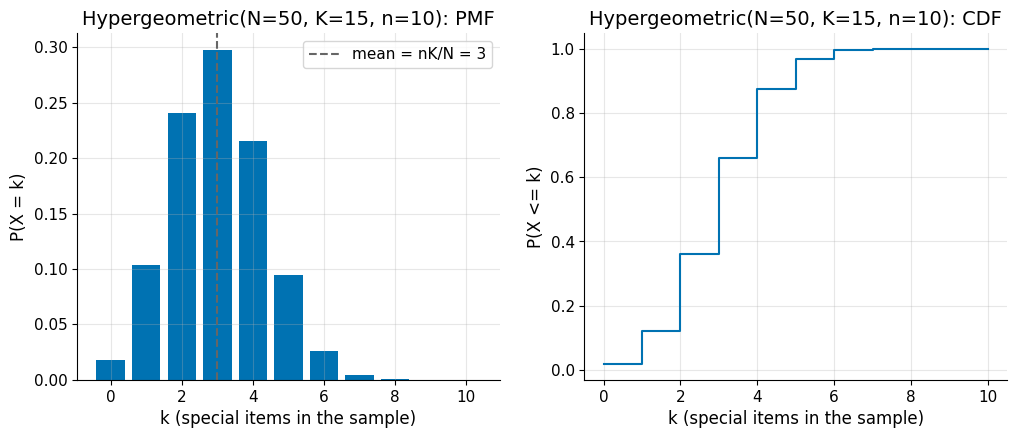

In [2]:
N_population = 50
K_special = 15
n_sample = 10
dist = stats.hypergeom(M=N_population, n=K_special, N=n_sample)
k_values = np.arange(0, n_sample + 1)

fig, (ax_pmf, ax_cdf) = plt.subplots(1, 2, figsize=(12, 4.5))
ax_pmf.bar(k_values, dist.pmf(k_values), color=MAIN)
ax_pmf.axvline(dist.mean(), color=NEUTRAL, linestyle="--", label="mean = nK/N = 3")
ax_pmf.set_title("Hypergeometric(N=50, K=15, n=10): PMF")
ax_pmf.set_xlabel("k (special items in the sample)")
ax_pmf.set_ylabel("P(X = k)")
ax_pmf.legend()

ax_cdf.step(k_values, dist.cdf(k_values), where="post", color=MAIN)
ax_cdf.set_title("Hypergeometric(N=50, K=15, n=10): CDF")
ax_cdf.set_xlabel("k (special items in the sample)")
ax_cdf.set_ylabel("P(X <= k)")
plt.show()

### 7.2 Hypergeometric vs Binomial: the finite-population correction
Same mean n K / N = 3. Without replacement (Hypergeometric) the distribution is narrower than with replacement (Binomial).

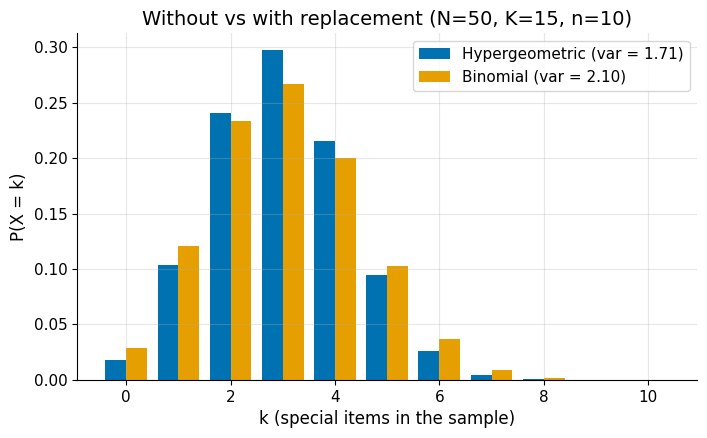

In [3]:
binomial_dist = stats.binom(n=n_sample, p=K_special / N_population)
fig, ax = plt.subplots()
width = 0.4
ax.bar(k_values - width / 2, dist.pmf(k_values), width=width, color=MAIN, label=f"Hypergeometric (var = {dist.var():.2f})")
ax.bar(k_values + width / 2, binomial_dist.pmf(k_values), width=width, color=SIM, label=f"Binomial (var = {binomial_dist.var():.2f})")
ax.set_title("Without vs with replacement (N=50, K=15, n=10)")
ax.set_xlabel("k (special items in the sample)")
ax.set_ylabel("P(X = k)")
ax.legend()
plt.show()

### 7.3 When does the Binomial become good?
Fixing the sample size n = 10 and the fraction K/N = 0.3, we grow the population. The maximum PMF difference shrinks toward 0.

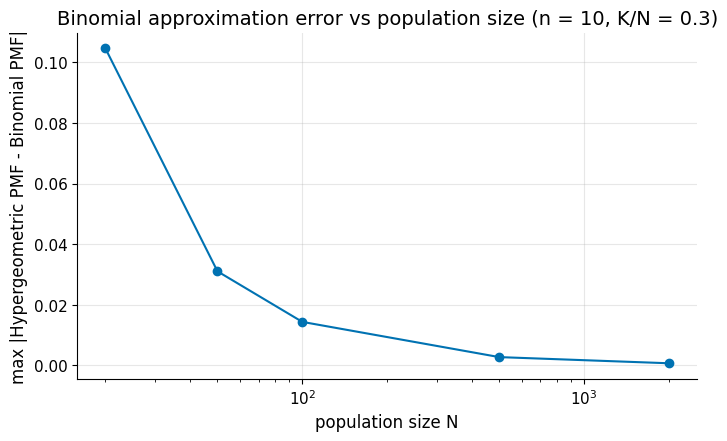

In [4]:
population_sizes = [20, 50, 100, 500, 2000]
max_differences = []
for population in population_sizes:
    hyper = stats.hypergeom(M=population, n=int(0.3 * population), N=10)
    binom = stats.binom(n=10, p=0.3)
    max_differences.append(np.max(np.abs(hyper.pmf(k_values) - binom.pmf(k_values))))

fig, ax = plt.subplots()
ax.plot(population_sizes, max_differences, "o-", color=MAIN)
ax.set_xscale("log")
ax.set_title("Binomial approximation error vs population size (n = 10, K/N = 0.3)")
ax.set_xlabel("population size N")
ax.set_ylabel("max |Hypergeometric PMF - Binomial PMF|")
plt.show()

### 7.4 Effect of K
For N = 50, n = 10, a larger number of special items K moves the distribution right.

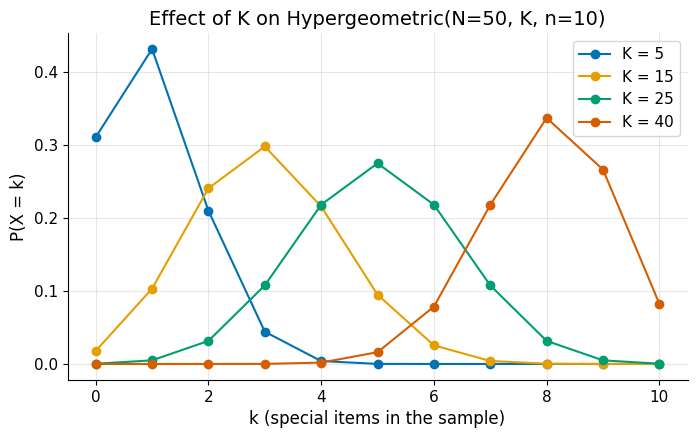

In [5]:
fig, ax = plt.subplots()
for K_value, color in zip([5, 15, 25, 40], COLORS):
    ax.plot(k_values, stats.hypergeom(M=50, n=K_value, N=10).pmf(k_values), "o-", color=color, label=f"K = {K_value}")
ax.set_title("Effect of K on Hypergeometric(N=50, K, n=10)")
ax.set_xlabel("k (special items in the sample)")
ax.set_ylabel("P(X = k)")
ax.legend()
plt.show()

## 8. 3D visuals

### 8.1 Static: PMF over (k, K) for fixed N = 50, n = 10

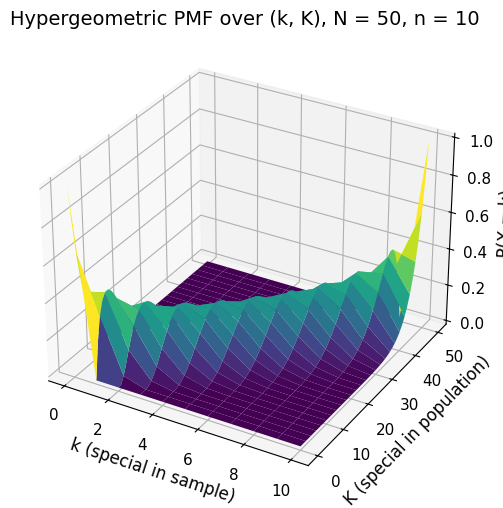

In [6]:
K_values = np.arange(0, 51)
k_values = np.arange(0, 11)
K_grid, k_grid = np.meshgrid(K_values, k_values)
Z = stats.hypergeom.pmf(k_grid, 50, K_grid, 10)       # scipy order: k, M, n(special), N(sample)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(k_grid, K_grid, Z, cmap="viridis", edgecolor="none")
ax.set_title("Hypergeometric PMF over (k, K), N = 50, n = 10")
ax.set_xlabel("k (special in sample)")
ax.set_ylabel("K (special in population)")
ax.set_zlabel("P(X = k)")
ax.view_init(elev=30, azim=-60)
plt.show()

### 8.2 Interactive Plotly version

In [7]:
fig = go.Figure(go.Surface(x=k_values, y=K_values, z=Z.T, colorscale="Viridis"))
fig.update_layout(title="Hypergeometric PMF over (k, K), N = 50, n = 10", width=750, height=550,
                  scene=dict(xaxis_title="k (special in sample)", yaxis_title="K (special in population)", zaxis_title="P(X = k)"))
fig.show()

## 9. Simulation vs theory

### 9.1 Histogram against the PMF
We literally draw without replacement: shuffle a box of 50 items (15 special) and take 10. Repeat 20,000 times.

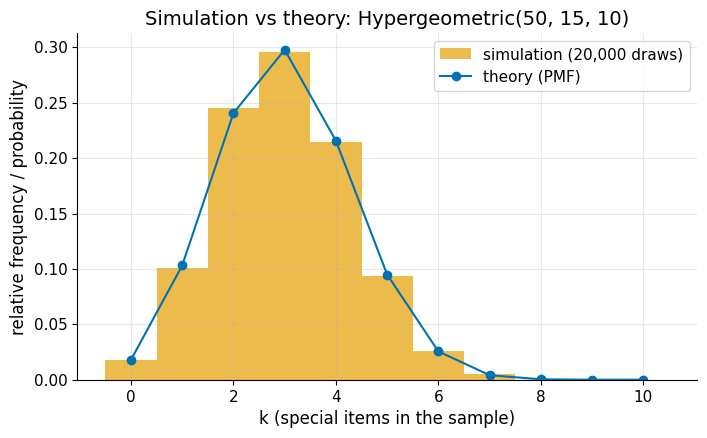

sample variance 1.721  theory 1.714  binomial would give 2.1


In [8]:
box = np.array([1] * K_special + [0] * (N_population - K_special))     # 1 = special item
counts = []
for _ in range(20_000):
    sample = rng.choice(box, size=n_sample, replace=False)
    counts.append(sample.sum())
counts = np.array(counts)

fig, ax = plt.subplots()
ax.hist(counts, bins=np.arange(0, 12) - 0.5, density=True, color=SIM, alpha=0.7, label="simulation (20,000 draws)")
ax.plot(k_values, dist.pmf(k_values), "o-", color=MAIN, label="theory (PMF)")
ax.set_title("Simulation vs theory: Hypergeometric(50, 15, 10)")
ax.set_xlabel("k (special items in the sample)")
ax.set_ylabel("relative frequency / probability")
ax.legend()
plt.show()
print("sample variance", counts.var().round(3), " theory", round(dist.var(), 3), " binomial would give", round(binomial_dist.var(), 3))

### 9.2 Running mean converges to nK/N

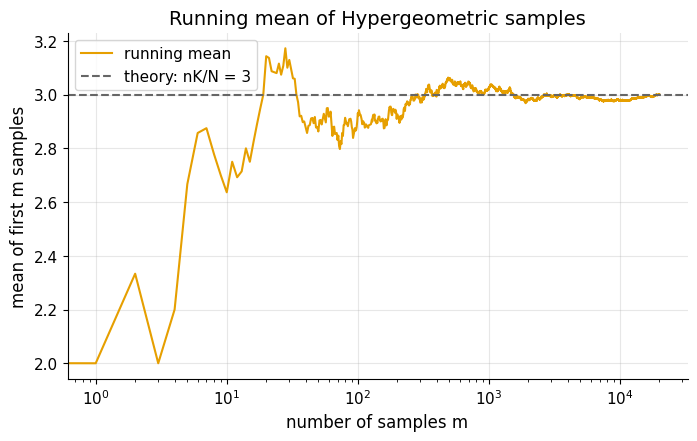

In [9]:
running_mean = np.cumsum(counts) / np.arange(1, len(counts) + 1)

fig, ax = plt.subplots()
ax.plot(running_mean, color=SIM, label="running mean")
ax.axhline(dist.mean(), color=NEUTRAL, linestyle="--", label="theory: nK/N = 3")
ax.set_title("Running mean of Hypergeometric samples")
ax.set_xlabel("number of samples m")
ax.set_ylabel("mean of first m samples")
ax.set_xscale("log")
ax.legend()
plt.show()

## 10. `scipy.stats` cheat sheet

Keywords avoid the confusing naming: `M` = population, `n` = special items, `N` = sample size.

In [10]:
dist = stats.hypergeom(M=500, n=25, N=20)
print("pmf(0)      P(X = 0)   :", round(dist.pmf(0), 5))
print("cdf(1)      P(X <= 1)  :", round(dist.cdf(1), 5))
print("sf(1)       P(X >= 2)  :", round(dist.sf(1), 5))
print("ppf(0.95)   :", dist.ppf(0.95))
print("rvs(5)      :", dist.rvs(size=5, random_state=1))
print("mean, var   :", dist.mean(), round(dist.var(), 4))
print("interval(.9):", dist.interval(0.9))

pmf(0)      P(X = 0)   : 0.35119
cdf(1)      P(X <= 1)  : 0.73628
sf(1)       P(X >= 2)  : 0.26372
ppf(0.95)   : 3.0
rvs(5)      : [1 2 1 3 1]
mean, var   : 1.0 0.9138
interval(.9): (np.float64(0.0), np.float64(3.0))


**Fisher's exact test** uses this distribution on a 2x2 table: rows are groups, columns are outcomes.

In [11]:
#                 improved  not improved
table = [[12, 3],     # new treatment (15 patients)
         [5, 10]]     # old treatment (15 patients)
odds_ratio, p_value = stats.fisher_exact(table, alternative="greater")

# The same p-value as a Hypergeometric tail: 30 patients, 17 improved in total, 15 got the new treatment.
tail = stats.hypergeom(M=30, n=17, N=15).sf(11)          # P(X >= 12)
print(f"Fisher exact p-value = {p_value:.5f}, hypergeometric tail = {tail:.5f}")
assert np.isclose(p_value, tail)

Fisher exact p-value = 0.01266, hypergeometric tail = 0.01266


## 11. Real-world worked example: auditing a lot of parts

**Scenario (illustrative numbers).** A supplier ships a lot of **N = 500 items** that contains **K = 25 defective** items (5 %), unknown to the buyer. An inspector draws **n = 20 items** without replacement and checks them. $X$ = number of defectives found, $X\sim\text{Hypergeom}(500,25,20)$.

**Questions**
1. What is the probability of finding **no defectives** ($P(X=0)$)?
2. What is $P(X\ge2)$?
3. What **sample size** is needed so that $P(\text{detect at least one defective})\ge95\%$?
4. How does the exact answer compare with the Binomial approximation?

### 11.1 By hand
**Q1.** $P(X=0)=\dfrac{\binom{475}{20}}{\binom{500}{20}}=\dfrac{475}{500}\cdot\dfrac{474}{499}\cdot\dfrac{473}{498}\cdots\dfrac{456}{481}$ (the product of 20 factors: the chance that each successive draw is non-defective). Each factor is close to $0.95$, so the answer is about $0.95^{20}=0.358$; the exact product is computed in the code below.

**Q2.** $P(X\ge2)=1-P(0)-P(1)$ with $P(1)=\dfrac{\binom{25}{1}\binom{475}{19}}{\binom{500}{20}}$.

**Q3.** We need the smallest $n$ with $1-\dfrac{\binom{475}{n}}{\binom{500}{n}}\ge0.95$, i.e. the product of the first $n$ factors falls to $0.05$ or below. Using the approximation $0.95^n\le0.05$: $n\ge\ln0.05/\ln0.95=58.4$. The exact answer is a little smaller (sampling without replacement removes defectives from the pool, making detection easier).

**Q4.** Binomial$(20,0.05)$: $P(0)=0.95^{20}=0.3585$.

In [12]:
import math

N_lot = 500
K_defective = 25
n_inspected = 20

def hypergeom_pmf_by_formula(k, N, K, n):
    # C(K, k) * C(N-K, n-k) / C(N, n), exactly as in the definition
    return math.comb(K, k) * math.comb(N - K, n - k) / math.comb(N, n)

p_zero_hand = hypergeom_pmf_by_formula(0, N_lot, K_defective, n_inspected)
p_one_hand = hypergeom_pmf_by_formula(1, N_lot, K_defective, n_inspected)
p_two_or_more_hand = 1 - p_zero_hand - p_one_hand

sample_size_hand = 1
while 1 - hypergeom_pmf_by_formula(0, N_lot, K_defective, sample_size_hand) < 0.95:
    sample_size_hand += 1
print(f"P(X=0) = {p_zero_hand:.5f}, P(X>=2) = {p_two_or_more_hand:.5f}, sample size for 95% detection = {sample_size_hand}")

P(X=0) = 0.35119, P(X>=2) = 0.26372, sample size for 95% detection = 56


### 11.2 In code with `scipy`, and the asserts
The approximation with the Binomial is computed alongside.

In [13]:
lot = stats.hypergeom(M=N_lot, n=K_defective, N=n_inspected)
approx = stats.binom(n=n_inspected, p=K_defective / N_lot)

p_zero_code = lot.pmf(0)
p_two_or_more_code = lot.sf(1)
sizes = np.arange(1, 200)
detect_prob = 1 - stats.hypergeom(M=N_lot, n=K_defective, N=sizes).pmf(0)
sample_size_code = sizes[np.argmax(detect_prob >= 0.95)]

assert np.isclose(p_zero_hand, p_zero_code)
assert np.isclose(p_two_or_more_hand, p_two_or_more_code)
assert sample_size_hand == sample_size_code
print(f"exact:    P(X=0) = {p_zero_code:.4f}, P(X>=2) = {p_two_or_more_code:.4f}")
print(f"binomial: P(X=0) = {approx.pmf(0):.4f}, P(X>=2) = {approx.sf(1):.4f}")
print(f"sample size for 95% detection (exact) = {sample_size_code}, Binomial approximation says {int(np.ceil(np.log(0.05) / np.log(0.95)))}")

exact:    P(X=0) = 0.3512, P(X>=2) = 0.2637
binomial: P(X=0) = 0.3585, P(X>=2) = 0.2642
sample size for 95% detection (exact) = 56, Binomial approximation says 59


### 11.3 Verify by simulation
Shuffle the lot and inspect 20 items, 50,000 times.

In [14]:
lot_items = np.array([1] * K_defective + [0] * (N_lot - K_defective))
found = np.empty(50_000, dtype=int)
for i in range(len(found)):
    found[i] = rng.choice(lot_items, size=n_inspected, replace=False).sum()

print(f"P(X=0):  exact {p_zero_code:.4f}  simulated {np.mean(found == 0):.4f}")
print(f"P(X>=2): exact {p_two_or_more_code:.4f}  simulated {np.mean(found >= 2):.4f}")
assert abs(np.mean(found == 0) - p_zero_code) < 0.01
assert abs(np.mean(found >= 2) - p_two_or_more_code) < 0.01

P(X=0):  exact 0.3512  simulated 0.3513
P(X>=2): exact 0.2637  simulated 0.2621


### 11.4 Plots with the regions shaded

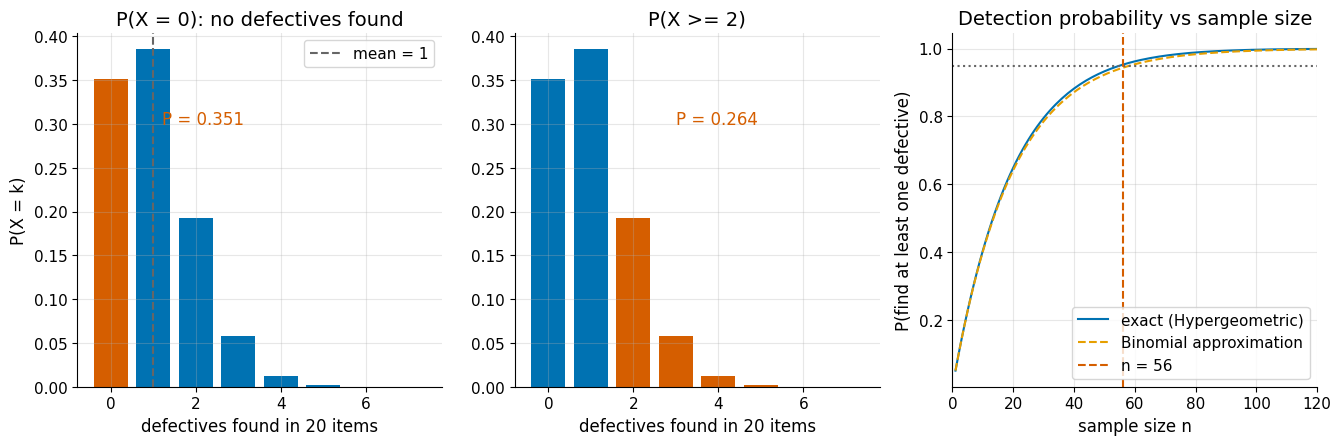

In [15]:
k_values = np.arange(0, 8)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

axes[0].bar(k_values, lot.pmf(k_values), color=MAIN)
axes[0].bar([0], [p_zero_code], color=HIGHLIGHT)
axes[0].axvline(lot.mean(), color=NEUTRAL, linestyle="--", label="mean = 1")
axes[0].set_title("P(X = 0): no defectives found")
axes[0].text(1.2, 0.3, f"P = {p_zero_code:.3f}", color=HIGHLIGHT, fontsize=12)
axes[0].set_xlabel("defectives found in 20 items")
axes[0].set_ylabel("P(X = k)")
axes[0].legend()

axes[1].bar(k_values, lot.pmf(k_values), color=MAIN)
tail = k_values >= 2
axes[1].bar(k_values[tail], lot.pmf(k_values[tail]), color=HIGHLIGHT)
axes[1].set_title("P(X >= 2)")
axes[1].text(3, 0.3, f"P = {p_two_or_more_code:.3f}", color=HIGHLIGHT, fontsize=12)
axes[1].set_xlabel("defectives found in 20 items")

axes[2].plot(sizes, detect_prob, color=MAIN, label="exact (Hypergeometric)")
axes[2].plot(sizes, 1 - 0.95**sizes, "--", color=SIM, label="Binomial approximation")
axes[2].axhline(0.95, color=NEUTRAL, linestyle=":")
axes[2].axvline(sample_size_code, color=HIGHLIGHT, linestyle="--", label=f"n = {sample_size_code}")
axes[2].set_xlim(0, 120)
axes[2].set_title("Detection probability vs sample size")
axes[2].set_xlabel("sample size n")
axes[2].set_ylabel("P(find at least one defective)")
axes[2].legend()
plt.show()

### 11.5 Interpretation and decision
- With a sample of 20, there is a **36 % chance the inspector finds nothing** even though 5 % of the lot is defective. A clean sample of 20 is weak evidence of a clean lot.
- The inspector finds **2 or more** defectives only about **26 %** of the time.
- **Decision:** to be **95 % sure of catching at least one defective** when the defect rate is 5 %, the inspector must sample about **56 items**. The Binomial rule of thumb (59) is slightly pessimistic here because the sample is more than 10 % of the lot.

### 11.6 Second example: a card game
In a 5-card poker hand from a 52-card deck, what is the probability of **2 or more aces**? $N=52$, $K=4$, $n=5$.

In [16]:
hand = stats.hypergeom(M=52, n=4, N=5)
by_hand = 1 - math.comb(48, 5) / math.comb(52, 5) - 4 * math.comb(48, 4) / math.comb(52, 5)
assert np.isclose(by_hand, hand.sf(1))
print(f"P(2+ aces in 5 cards) = {hand.sf(1):.4f}  (about 1 hand in {1 / hand.sf(1):.0f})")

P(2+ aces in 5 cards) = 0.0417  (about 1 hand in 24)


## 12. Where it is used

### Statistics
- **Fisher's exact test** for 2x2 tables with small counts (clinical trials, A/B tests with few events).
- **Audit and acceptance sampling:** deciding how many items to inspect to detect a defect rate.
- **Capture-recapture** estimates of population size.

### Data science
- **Gene-set enrichment analysis:** the chance that a pathway contains at least k of your top genes by chance is a Hypergeometric tail.
- **Sampling for labelling or QA** from a finite dataset: how many records to review so as to catch an error type.
- **Lottery and raffle odds.**

### ML and AI
- **Train/test splits without replacement:** the number of positives landing in the test set is Hypergeometric, which explains the variability of small test sets.
- **Mini-batch sampling without replacement** (an epoch) has hypergeometric class counts per batch.
- **Enrichment-style tests** for explaining which features or tokens are over-represented in a cluster.

## 13. Common pitfalls and misconceptions

- **Using Binomial when the sample is a large share of the population** (over about 10 %) overstates the variance and gives wrong tail probabilities.
- **Mixing up scipy's parameters:** `hypergeom(M, n, N)` means (population, special items, sample size). Use keywords.
- **Forgetting the support limits:** you cannot find more special items than $K$ or than $n$.
- **Assuming independence between draws:** they are negatively correlated, which is why the variance is smaller.
- **A clean sample is not a clean lot:** absence of defects in a small sample proves little (see Q1).

## 14. Exercises

1. A committee of 4 is picked at random from 6 women and 4 men. What is the probability it has exactly 2 women?
2. A deck has 52 cards. You draw 13 (a bridge hand). What is the probability of exactly 4 hearts?
3. Verify $E[X]=nK/N$ and the variance formula numerically for $N=30$, $K=12$, $n=8$ using the PMF.
4. A lot of 200 items has 10 defectives. How many items must be inspected to detect at least one defective with probability 90 %?
5. In a lottery you pick 6 numbers from 49 and 6 winning numbers are drawn. What is the probability of matching exactly 3? At least 4?
6. For $N=1000$, $K=300$, $n=10$ compare the Hypergeometric and Binomial probabilities of $X=3$. Then repeat with $n=400$.
7. (Harder) Use the 2x2 table [[8, 2], [1, 5]] and `fisher_exact`. Show that the p-value equals a Hypergeometric tail sum.
8. (Harder) Derive $\mathrm{Cov}(I_i,I_j)=-p(1-p)/(N-1)$ and explain why it is negative.

Solutions are at the end.

## 15. Summary table

| Item | Value |
|---|---|
| Parameters | N (population), K (special items), n (sample size) |
| Support | max(0, n-N+K) to min(n, K) |
| PMF | C(K,k) C(N-K,n-k) / C(N,n) |
| Mean | nK/N |
| Variance | n (K/N)(1-K/N)(N-n)/(N-1) |
| When to use | special items in a sample drawn without replacement from a finite population |
| `scipy` name | `scipy.stats.hypergeom(M=N, n=K, N=n)` |

## Solutions

In [17]:
print("1:", stats.hypergeom(M=10, n=6, N=4).pmf(2))
print("2:", stats.hypergeom(M=52, n=13, N=13).pmf(4))

d = stats.hypergeom(M=30, n=12, N=8)
ks = np.arange(0, 9)
mean_numeric = (ks * d.pmf(ks)).sum()
var_numeric = ((ks - mean_numeric) ** 2 * d.pmf(ks)).sum()
p = 12 / 30
print("3:", mean_numeric, 8 * p, var_numeric, 8 * p * (1 - p) * (30 - 8) / (30 - 1))

sizes = np.arange(1, 200)
need = sizes[np.argmax(1 - stats.hypergeom(M=200, n=10, N=sizes).pmf(0) >= 0.9)]
print("4: sample size =", need)

lottery = stats.hypergeom(M=49, n=6, N=6)
print("5: exactly 3:", lottery.pmf(3), " at least 4:", lottery.sf(3))
for n in (10, 400):
    print("6: n =", n, stats.hypergeom(M=1000, n=300, N=n).pmf(3 if n == 10 else 120), stats.binom(n, 0.3).pmf(3 if n == 10 else 120))

odds, p_val = stats.fisher_exact([[8, 2], [1, 5]], alternative="greater")
print("7:", p_val, stats.hypergeom(M=16, n=9, N=10).sf(7))

1: 0.4285714285714286
2: 0.23860800622185646
3: 3.1999999999999997 3.2 1.456551724137931 1.4565517241379309
4: sample size = 41
5: exactly 3: 0.017650403866870105  at least 4: 0.0009871411351522362
6: n = 10 0.26817131263929883 0.2668279319999998
6: n = 400 0.05613886960557161 0.04349407047516403
7: 0.024475524475524483 0.02447552447552448


**1.** $\binom62\binom42/\binom{10}4=15\cdot6/210\approx0.4286$.

**2.** $\binom{13}4\binom{39}9/\binom{52}{13}\approx0.2386$.

**3.** The numeric mean and variance match the formulas, including the FPC factor $(N-n)/(N-1)$.

**4.** Printed above (41 items out of 200).

**5.** Exactly 3 matches: about 0.0177; at least 4: about 0.00098.

**6.** For $n=10$ (1 % of the population) the two PMFs agree to about two decimals (0.268 vs 0.267). For $n=400$ (40 % of the population) the Binomial is clearly wrong: at the common mean $k=120$ it gives 0.043 against the exact 0.056, because it ignores the FPC and is too wide.

**7.** The p-value equals the tail $P(X\ge8)$ of Hypergeom($N=16$, $K=9$, $n=10$): the table has 9 total "successes" in column 1 and 10 in row 1, and the cell value 8 is the observed count.

**8.** $P(I_i=I_j=1)=\frac KN\frac{K-1}{N-1}$ and $p^2=\frac{K^2}{N^2}$, so $\mathrm{Cov}=\frac{K(K-1)}{N(N-1)}-\frac{K^2}{N^2}=\frac KN\Big[\frac{K-1}{N-1}-\frac KN\Big]=-\frac{K(N-K)}{N^2(N-1)}=-\frac{p(1-p)}{N-1}$. Negative because drawing a special item leaves fewer special items for the other draws.